<a href="https://colab.research.google.com/github/bisensamiksha/Samiksha_Task/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Section 2

Problem 2.1 - Generate Data

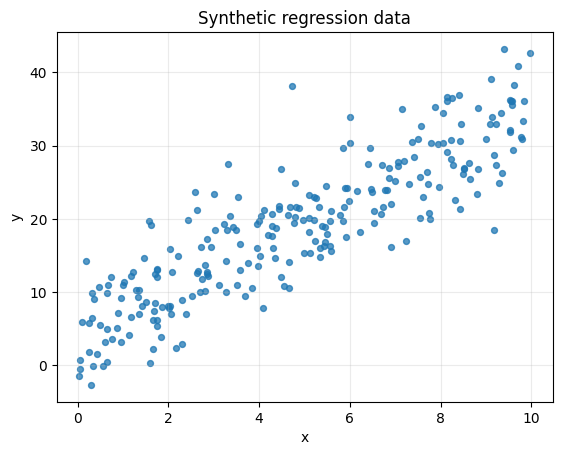

Input shape: torch.Size([250, 1])
Target shape: torch.Size([250, 1])


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# Example values: replace these with your own choices
a_true = 5.0          # intercept
b_true = 3.0          # slope
sigma_epsilon = 5.0   # noise level
n_samples = 250

# Make inputs between 0 and 10, then add noise to the line y = a + b*x
X = np.random.uniform(0, 10, n_samples)
y_obs = a_true + b_true * X + sigma_epsilon * np.random.randn(n_samples)

# Convert to PyTorch tensors: one row per observation, one column per value
X_tensor = torch.tensor(X, dtype=torch.float32).reshape(-1, 1)
y_tensor = torch.tensor(y_obs, dtype=torch.float32).reshape(-1, 1)

# Plot the noisy observations
plt.scatter(X, y_obs, s=18, alpha=0.75)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic regression data")
plt.grid(alpha=0.25)
plt.show()

print("Input shape:", X_tensor.shape)
print("Target shape:", y_tensor.shape)

Problem 2.2 - Make a PyTorch dataset object “TensorDataset”

In [2]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_tensor, y_tensor)

batch_size = 32  # 32 of 250 examples
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

print("Number of examples:", len(train_dataset))
print("Number of batches:", len(train_loader))

# Inspect one mini-batch
x_batch, y_batch = next(iter(train_loader))
print("Input batch shape:", x_batch.shape)
print("Target batch shape:", y_batch.shape)

# See how many examples are in each batch
batch_sizes = [len(xb) for xb, yb in train_loader]
print("Examples per batch:", batch_sizes)

Number of examples: 250
Number of batches: 8
Input batch shape: torch.Size([32, 1])
Target batch shape: torch.Size([32, 1])
Examples per batch: [32, 32, 32, 32, 32, 32, 32, 26]


Problem 2.3 - Create one-dimensional linear predictive model

In [3]:
from torch import nn

model = nn.Sequential(
    nn.Linear(in_features=1, out_features=1)
)

# Look at the model's initial parameters
print("Initial slope (weight):", model[0].weight.item())
print("Initial intercept (bias):", model[0].bias.item())

# Check that it maps inputs to predictions with the right shape
example_predictions = model(X_tensor[:5])
print("Prediction shape:", example_predictions.shape)
print("First five predictions:\n", example_predictions)

Initial slope (weight): -0.023113608360290527
Initial intercept (bias): -0.15665030479431152
Prediction shape: torch.Size([5, 1])
First five predictions:
 tensor([[-0.3448],
        [-0.2559],
        [-0.2746],
        [-0.1576],
        [-0.3700]], grad_fn=<AddmmBackward0>)


Problem 2.4 - Define cost function

In [4]:
cost_function = nn.MSELoss()

# Get one mini-batch and make predictions for it
x_batch, y_batch = next(iter(train_loader))
predictions = model(x_batch)

# Compare predictions with the correct targets
loss = cost_function(predictions, y_batch)

print("Prediction shape:", predictions.shape)
print("Target shape:", y_batch.shape)
print("Initial batch MSE:", loss.item())

Prediction shape: torch.Size([32, 1])
Target shape: torch.Size([32, 1])
Initial batch MSE: 565.8001708984375


Problem 2.5 - Choose optimizer and learning rate

In [5]:
learning_rate = 0.0001

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate
)

print("Learning rate:", optimizer.param_groups[0]["lr"])

Learning rate: 0.0001


Problem 2.6 - Train your model and plot training cost curve

In [11]:
nr_epochs = 1000

initial_slope = model[0].weight.item()
initial_intercept = model[0].bias.item()

list_of_minibatch_costs = []
list_of_epoch_costs = []

for epoch_i in range(nr_epochs):
    total_epoch_cost = 0.0
    examples_seen = 0

    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()                  # clear previous gradients

        predictions = model(x_batch)            # predict for this batch
        loss = cost_function(predictions, y_batch)

        loss.backward()                         # calculate gradients
        optimizer.step()                        # update weight and bias

        list_of_minibatch_costs.append(loss.item())
        total_epoch_cost += loss.item() * len(x_batch)
        examples_seen += len(x_batch)

    list_of_epoch_costs.append(total_epoch_cost / examples_seen)

with torch.no_grad():
    final_predictions = model(X_tensor)
    final_data_mse = cost_function(final_predictions, y_tensor).item()

print("Initial slope:", initial_slope)
print("Initial intercept:", initial_intercept)
print("Trained slope:", model[0].weight.item())
print("Trained intercept:", model[0].bias.item())
print("MSE on all data after training:", final_data_mse)

Initial slope: 3.09246826171875
Initial intercept: 3.9769251346588135
Trained slope: 3.0569725036621094
Trained intercept: 4.216177940368652
MSE on all data after training: 22.851547241210938


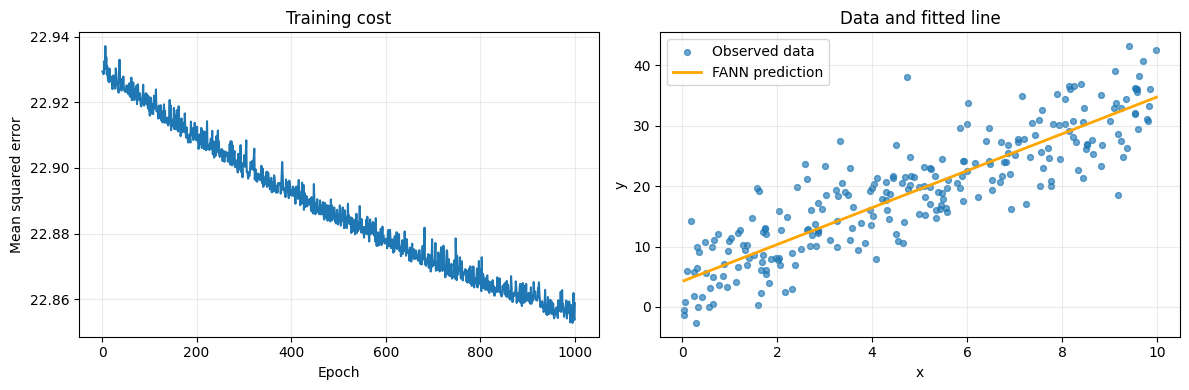

First epoch average cost: 22.929366439819336
Last epoch average cost: 22.858797668457033


In [12]:
with torch.no_grad():
    predictions = model(X_tensor).numpy().flatten()

# Sort x-values so the prediction line is drawn from left to right
sort_order = np.argsort(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training cost curve
axes[0].plot(range(1, nr_epochs + 1), list_of_epoch_costs)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean squared error")
axes[0].set_title("Training cost")
axes[0].grid(alpha=0.25)

# Data and fitted model
axes[1].scatter(X, y_obs, s=18, alpha=0.65, label="Observed data")
axes[1].plot(
    X[sort_order],
    predictions[sort_order],
    color="orange",
    linewidth=2,
    label="FANN prediction"
)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Data and fitted line")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("First epoch average cost:", list_of_epoch_costs[0])
print("Last epoch average cost:", list_of_epoch_costs[-1])

What if we continue training for more 1000 epoch:

Trained slope: 3.0318541526794434
Trained intercept: 4.374025344848633
MSE on all data: 22.819129943847656


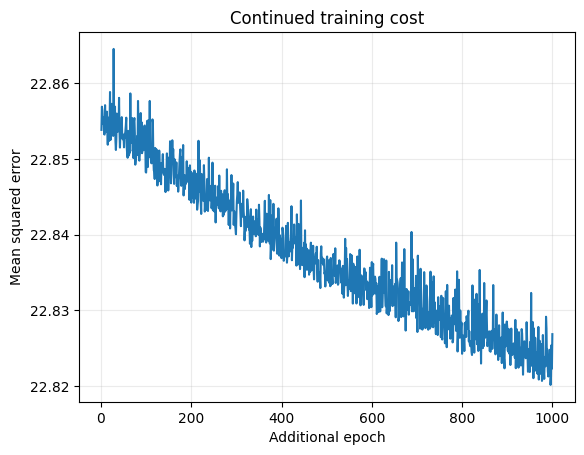

In [13]:
extra_epochs = 1000
extra_epoch_costs = []

for epoch_i in range(extra_epochs):
    total_epoch_cost = 0.0
    examples_seen = 0

    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = cost_function(predictions, y_batch)
        loss.backward()
        optimizer.step()

        total_epoch_cost += loss.item() * len(x_batch)
        examples_seen += len(x_batch)

    extra_epoch_costs.append(total_epoch_cost / examples_seen)

with torch.no_grad():
    final_data_mse = cost_function(model(X_tensor), y_tensor).item()

print("Trained slope:", model[0].weight.item())
print("Trained intercept:", model[0].bias.item())
print("MSE on all data:", final_data_mse)

plt.plot(range(1, extra_epochs + 1), extra_epoch_costs)
plt.xlabel("Additional epoch")
plt.ylabel("Mean squared error")
plt.title("Continued training cost")
plt.grid(alpha=0.25)
plt.show()

MSE decreased from about 22.85 to 22.82 over another 1,000 epochs. It’s still improving, but only slightly, so we should stop for now rather than train more.

Problem 2.7 - Make predictions

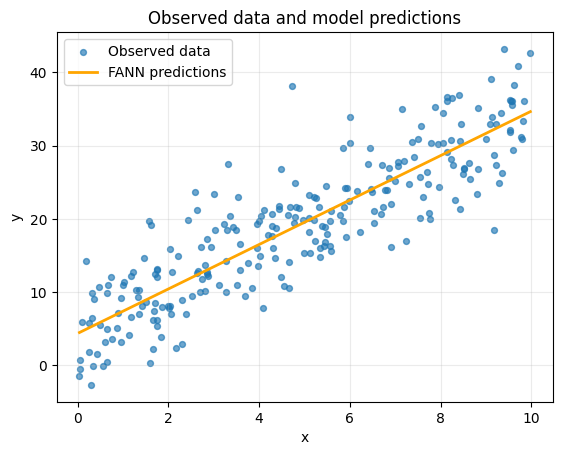

In [15]:
with torch.no_grad():
    y_preds = model(X_tensor).squeeze(1).numpy()

sort_order = np.argsort(X)

plt.scatter(X, y_obs, s=18, alpha=0.65, label="Observed data")
plt.plot(
    X[sort_order],
    y_preds[sort_order],
    color="orange",
    linewidth=2,
    label="FANN predictions"
)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Observed data and model predictions")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Problem 2.8 - Print and look at your final model parameters

In [16]:
learned_slope = model[0].weight.item()
learned_intercept = model[0].bias.item()

print("True slope:     ", b_true)
print("Learned slope:  ", learned_slope)
print("True intercept: ", a_true)
print("Learned intercept:", learned_intercept)

True slope:      3.0
Learned slope:   3.0318541526794434
True intercept:  5.0
Learned intercept: 4.374025344848633


In [17]:
for p in model.named_parameters():
    print(p)

('0.weight', Parameter containing:
tensor([[3.0319]], requires_grad=True))
('0.bias', Parameter containing:
tensor([4.3740], requires_grad=True))


#Section 3

Exercise 3.1 - A single artificial neuron

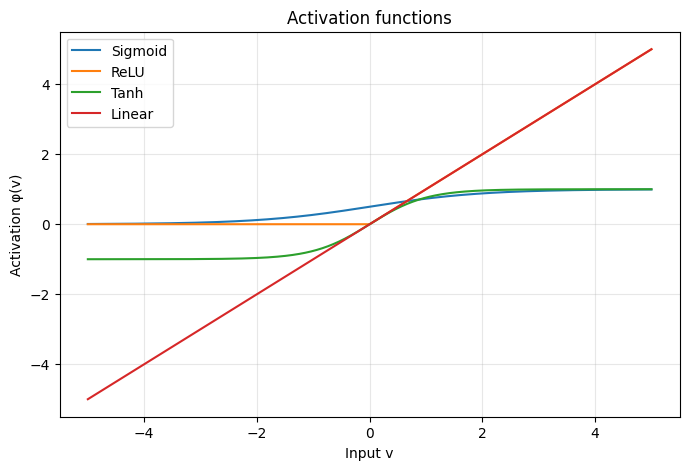

In [18]:
v = np.linspace(-5, 5, 400)

sigmoid = 1 / (1 + np.exp(-v))
relu = np.maximum(0, v)
tanh = np.tanh(v)
linear = v

plt.figure(figsize=(8, 5))
plt.plot(v, sigmoid, label="Sigmoid")
plt.plot(v, relu, label="ReLU")
plt.plot(v, tanh, label="Tanh")
plt.plot(v, linear, label="Linear")
plt.xlabel("Input v")
plt.ylabel("Activation φ(v)")
plt.title("Activation functions")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

(b) With one input, the neuron has two adjustable parameters: its weight and bias.

(c) With d inputs, it has d weights plus one bias: \(d+1\) parameters.

Exercise 3.2: Number of tunable parameters in Multilayer FANN

The diagram in Section 3.2 has architecture 2–5–2–1: 2 inputs, then hidden layers with 5 and 2 neurons, then 1 output. Each neuron has one weight per connection coming into it, plus one bias.

Count each transition:
- 2 inputs → 5 neurons: (2*5) weights + 5 biases = 15
- 5 neurons → 2 neurons: (5*2) weights + 2 biases = 12
- 2 neurons → 1 output: (2*1) weights + 1 bias = 3

Total: 15 + 12 + 3 = 30 trainable parameters.



**1. The first layer turns the two inputs into five values**

Each of the five neurons receives both inputs, but each has its **own** weights and bias. For the first neuron:

$h_1=\varphi(w_{10}+w_{11}x_1+w_{12}x_2)$

Here, $w_{11}$ controls how much $x_1$ affects this neuron, $w_{12}$ controls how much $x_2$ affect it, and $w_{10}$ is its bias. The result is $h_1$.

The other four neurons do their own calculations, giving five results:

$h_1,\ h_2,\ h_3,\ h_4,\ h_5$

The $h$ symbols just name these intermediate results.

**2. The second layer combines those five values into two**

Each neuron in this layer receives all five first-layer results. For the first neuron:

$z_1=\varphi(v_{10}+v_{11}h_1+v_{12}h_2+v_{13}h_3+v_{14}h_4+v_{15}h_5)$

It produces $z_1$. The second neuron does a similar calculation with its own weights and bias, producing $z_2$.

So this layer passes along two results: $z_1$ and $z_2$.

**3. The output neuron combines those two values**

The final neuron receives $z_1$ and $z_2$, then calculates:

$y=\varphi(w_{\text{out},0}+w_{\text{out},1}z_1+w_{\text{out},2}z_2)$

That $y$ is the network’s output for the original apartment inputs.

Exercise 3.4: Interpretability of MSE vs RMSE

MSE is measured in kilograms squared $(\text{kg}^2)$, because the
errors are squared. RMSE is measured in kilograms $(\text{kg})$, because taking the square root returns it to the original unit.

Exercise 3.5: Fast weight updating

The exercise has 64 million examples and a batch size of 64. That gives:

$64{,}000{,}000 \div 64 = 1{,}000{,}000$

mini-batches per epoch. After 3 epochs:
- Full-batch gradient descent: 1 update per epoch × 3 = 3 updates
- Mini-batch SGD: 1,000,000 updates per epoch × 3 = 3,000,000 updates

Each SGD update uses only 64 examples, so it can adjust the model frequently without waiting to process all 64 million examples first leading to faster learning.

Why that helps: the model gets frequent feedback, and each update needs less memory and computation than calculating a gradient from all 64 million examples. The small randomness in each update can also help it move past shallow dips in the loss.

The tradeoff: each batch gives an imperfect estimate of the overall direction, so updates are noisier. The loss may fluctuate, and choosing a suitable learning rate matters. Full-batch gradient descent gives a steadier update, but it must process all 64 million examples before making each one.

Mini-batches are a practical middle ground: frequent, relatively inexpensive updates, with some noise.

3.6: Reduced problems with local minima

Gradient Descent follows the loss downhill using its gradient. If it reaches a local minimum, the gradient can become very small, so it may stop even though a lower global minimum exists elsewhere. Stochastic Gradient Descent estimates the gradient from random mini-batches, making its updates noisier. That randomness can sometimes help the model move out of a shallow local minimum, although it does not guarantee finding the global minimum.

# Section 5


Exercise B

In [23]:
#Upload the file
from google.colab import files

uploaded_files = files.upload()
csv_name = next(iter(uploaded_files))
print("Uploaded:", csv_name)

Saving dataset_Marvin_Minsky.csv to dataset_Marvin_Minsky (1).csv
Uploaded: dataset_Marvin_Minsky (1).csv


In [24]:
import numpy as np

my_data = np.genfromtxt(
    csv_name,
    delimiter=",",
    skip_header=1
)

print("Data shape:", my_data.shape)
print("First five rows:\n", my_data[:5])

Data shape: (200, 2)
First five rows:
 [[44.534092   2.1546903]
 [17.457317   1.831702 ]
 [40.618217   2.1354475]
 [67.10228    2.3688064]
 [11.144817   1.2648408]]


Input shape: torch.Size([200, 1])
Target shape: torch.Size([200, 1])


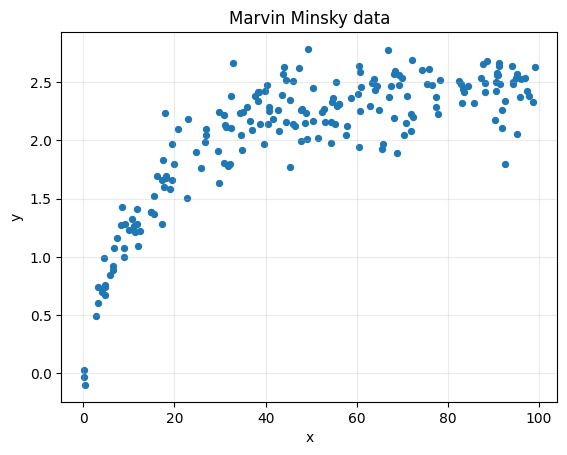

In [21]:
import torch
import matplotlib.pyplot as plt

X = torch.tensor(my_data[:, 0], dtype=torch.float32).reshape(-1, 1)
y_obs = torch.tensor(my_data[:, 1], dtype=torch.float32).reshape(-1, 1)

print("Input shape:", X.shape)
print("Target shape:", y_obs.shape)

plt.scatter(X.numpy().ravel(), y_obs.numpy().ravel(), s=18)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Marvin Minsky data")
plt.grid(alpha=0.25)
plt.show()

Creating the dataset and mini-batch loader

In [22]:
from torch.utils.data import TensorDataset, DataLoader

my_dataset = TensorDataset(X, y_obs)

batch_size = 16
my_dataloader = DataLoader(
    my_dataset,
    batch_size=batch_size,
    shuffle=True
)

print("Examples:", len(my_dataset))
print("Batches per epoch:", len(my_dataloader))

x_batch, y_batch = next(iter(my_dataloader))
print("Input batch shape:", x_batch.shape)
print("Target batch shape:", y_batch.shape)

Examples: 200
Batches per epoch: 13
Input batch shape: torch.Size([16, 1])
Target batch shape: torch.Size([16, 1])


Defining the 1–3–3–1 network

In [25]:
from torch import nn

model = nn.Sequential(
    nn.Linear(1, 3),
    nn.Tanh(),

    nn.Linear(3, 3),
    nn.Tanh(),

    nn.Linear(3, 1)
)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
print("Output shape:", model(x_batch).shape)

Sequential(
  (0): Linear(in_features=1, out_features=3, bias=True)
  (1): Tanh()
  (2): Linear(in_features=3, out_features=3, bias=True)
  (3): Tanh()
  (4): Linear(in_features=3, out_features=1, bias=True)
)
Trainable parameters: 22
Output shape: torch.Size([16, 1])


Setting the loss and optimizer : For regression, we’ll use MSE.

In [26]:
# Keep X as the original values for plotting; use X_scaled as model input
x_min = X.min()
x_max = X.max()
X_scaled = 2 * (X - x_min) / (x_max - x_min) - 1

# Rebuild the dataset and loader using the scaled inputs
my_dataset = TensorDataset(X_scaled, y_obs)
my_dataloader = DataLoader(
    my_dataset,
    batch_size=16,
    shuffle=True
)

cost_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

x_batch, y_batch = next(iter(my_dataloader))
print("Scaled input range:", X_scaled.min().item(), "to", X_scaled.max().item())
print("Batch shapes:", x_batch.shape, y_batch.shape)

Scaled input range: -1.0 to 1.0
Batch shapes: torch.Size([16, 1]) torch.Size([16, 1])


Training the nonlinear network: This loop makes predictions for each mini-batch, calculates MSE, and lets Adam update the network. It records loss after each batch so we can plot the assignment’s cost curve. Rerunning it continues training the same model.

In [27]:

nr_epochs = 1000

list_of_minibatch_costs = []
list_of_epoch_costs = []

for epoch_i in range(nr_epochs):
    total_epoch_cost = 0.0
    examples_seen = 0

    for x_batch, y_batch in my_dataloader:
        optimizer.zero_grad()

        predictions = model(x_batch)
        loss = cost_function(predictions, y_batch)

        loss.backward()
        optimizer.step()

        list_of_minibatch_costs.append(loss.item())
        total_epoch_cost += loss.item() * len(x_batch)
        examples_seen += len(x_batch)

    list_of_epoch_costs.append(total_epoch_cost / examples_seen)

# Evaluate the trained model on all examples
with torch.no_grad():
    all_predictions = model(X_scaled)
    final_mse = cost_function(all_predictions, y_obs).item()

print("Final MSE:", final_mse)

Final MSE: 0.03848904371261597


MSE is below 0.1, so now lets plot the training cost and compare it with the prediction and data set

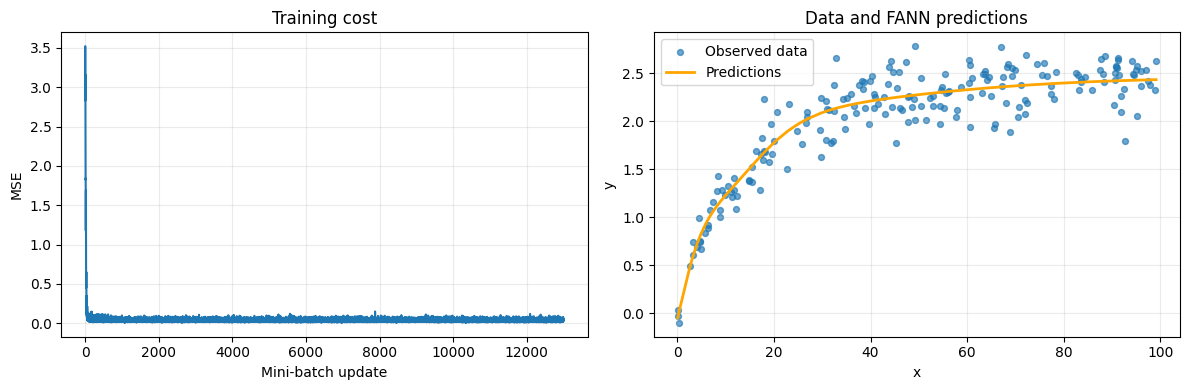

In [28]:
with torch.no_grad():
    all_predictions = model(X_scaled).numpy().ravel()

x_values = X.numpy().ravel()
y_values = y_obs.numpy().ravel()
sort_order = np.argsort(x_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cost after each mini-batch update
axes[0].plot(list_of_minibatch_costs)
axes[0].set_xlabel("Mini-batch update")
axes[0].set_ylabel("MSE")
axes[0].set_title("Training cost")
axes[0].grid(alpha=0.25)

# Observed data and model predictions
axes[1].scatter(x_values, y_values, s=18, alpha=0.65, label="Observed data")
axes[1].plot(
    x_values[sort_order],
    all_predictions[sort_order],
    color="orange",
    linewidth=2,
    label="Predictions"
)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Data and FANN predictions")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# Section 6

(a) Generating the data

Input shape: torch.Size([1000, 2])
Target shape: torch.Size([1000, 1])
Batches per epoch: 16


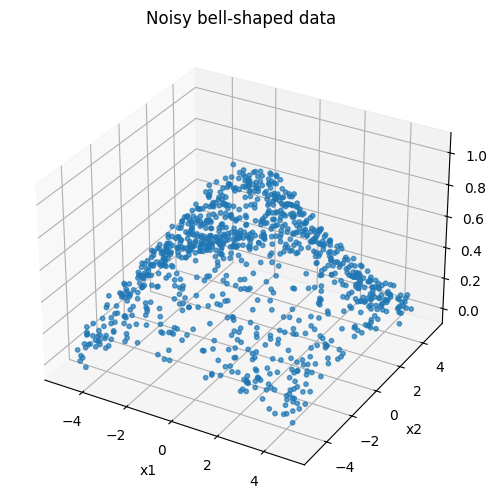

In [3]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

N = 1000
sigma_noise = 0.04

# Two inputs, each drawn uniformly from [-5, 5]
X_bell = 10 * torch.rand(N, 2) - 5

# Bell-shaped target plus Gaussian noise
squared_radius = (X_bell ** 2).sum(dim=1, keepdim=True)
y_bell = torch.exp(-squared_radius / 16) + sigma_noise * torch.randn(N, 1)

# Dataset and mini-batch loader
bell_dataset = TensorDataset(X_bell, y_bell)
batch_size_bell = 64
bell_loader = DataLoader(
    bell_dataset,
    batch_size=batch_size_bell,
    shuffle=True
)

print("Input shape:", X_bell.shape)
print("Target shape:", y_bell.shape)
print("Batches per epoch:", len(bell_loader))

# Plot the noisy data in 3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    X_bell[:, 0].numpy(),
    X_bell[:, 1].numpy(),
    y_bell[:, 0].numpy(),
    s=10,
    alpha=0.7
)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("Noisy bell-shaped data")
plt.show()

(b) Defining the two network architecture

In [4]:
from torch import nn

# Architecture I: 2 inputs -> 40 hidden neurons -> 1 output
model_small = nn.Sequential(
    nn.Linear(2, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
)

# Architecture II: 2 inputs -> 40 -> 40 -> 40 hidden neurons -> 1 output
model_deep = nn.Sequential(
    nn.Linear(2, 40),
    nn.ReLU(),
    nn.Linear(40, 40),
    nn.ReLU(),
    nn.Linear(40, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
)

print("Small model parameters:",
      sum(p.numel() for p in model_small.parameters()))
print("Deep model parameters:",
      sum(p.numel() for p in model_deep.parameters()))

x_batch_bell, y_batch_bell = next(iter(bell_loader))
print("Small model output shape:", model_small(x_batch_bell).shape)
print("Deep model output shape:", model_deep(x_batch_bell).shape)

Small model parameters: 161
Deep model parameters: 3441
Small model output shape: torch.Size([64, 1])
Deep model output shape: torch.Size([64, 1])


(c) Training for 400 epochs

In [5]:
criterion_bell = nn.MSELoss()

def train_fann(model, epochs=400, learning_rate=0.001):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    minibatch_costs = []

    for epoch in range(epochs):
        for x_batch, y_batch in bell_loader:
            optimizer.zero_grad()

            predictions = model(x_batch)
            loss = criterion_bell(predictions, y_batch)

            loss.backward()
            optimizer.step()

            minibatch_costs.append(loss.item())

    with torch.no_grad():
        final_mse = criterion_bell(model(X_bell), y_bell).item()

    return minibatch_costs, final_mse


costs_small, mse_small = train_fann(model_small)
costs_deep, mse_deep = train_fann(model_deep)

print("Small model final MSE:", mse_small)
print("Deep model final MSE:", mse_deep)
print("Learning rate: 0.001")

Small model final MSE: 0.0017928091110661626
Deep model final MSE: 0.0015857279067859054
Learning rate: 0.001


(d)

1. chosen learning rate is: 0.001
2. training cost curves as a function of the number of mini-batches

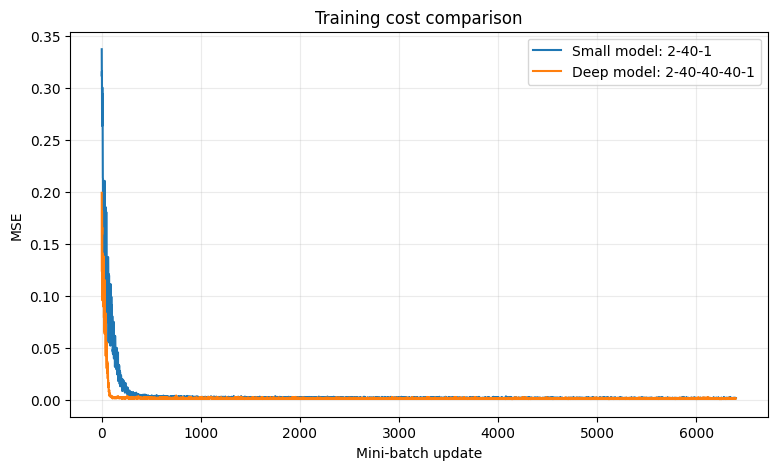

In [6]:
plt.figure(figsize=(9, 5))
plt.plot(costs_small, label="Small model: 2-40-1")
plt.plot(costs_deep, label="Deep model: 2-40-40-40-1")
plt.xlabel("Mini-batch update")
plt.ylabel("MSE")
plt.title("Training cost comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

3. Final cost function values (MSE): The 2–40–1 model achieved 0.001660, and the 2–40–40–40–1 model achieved 0.001569.

4. 3 plot

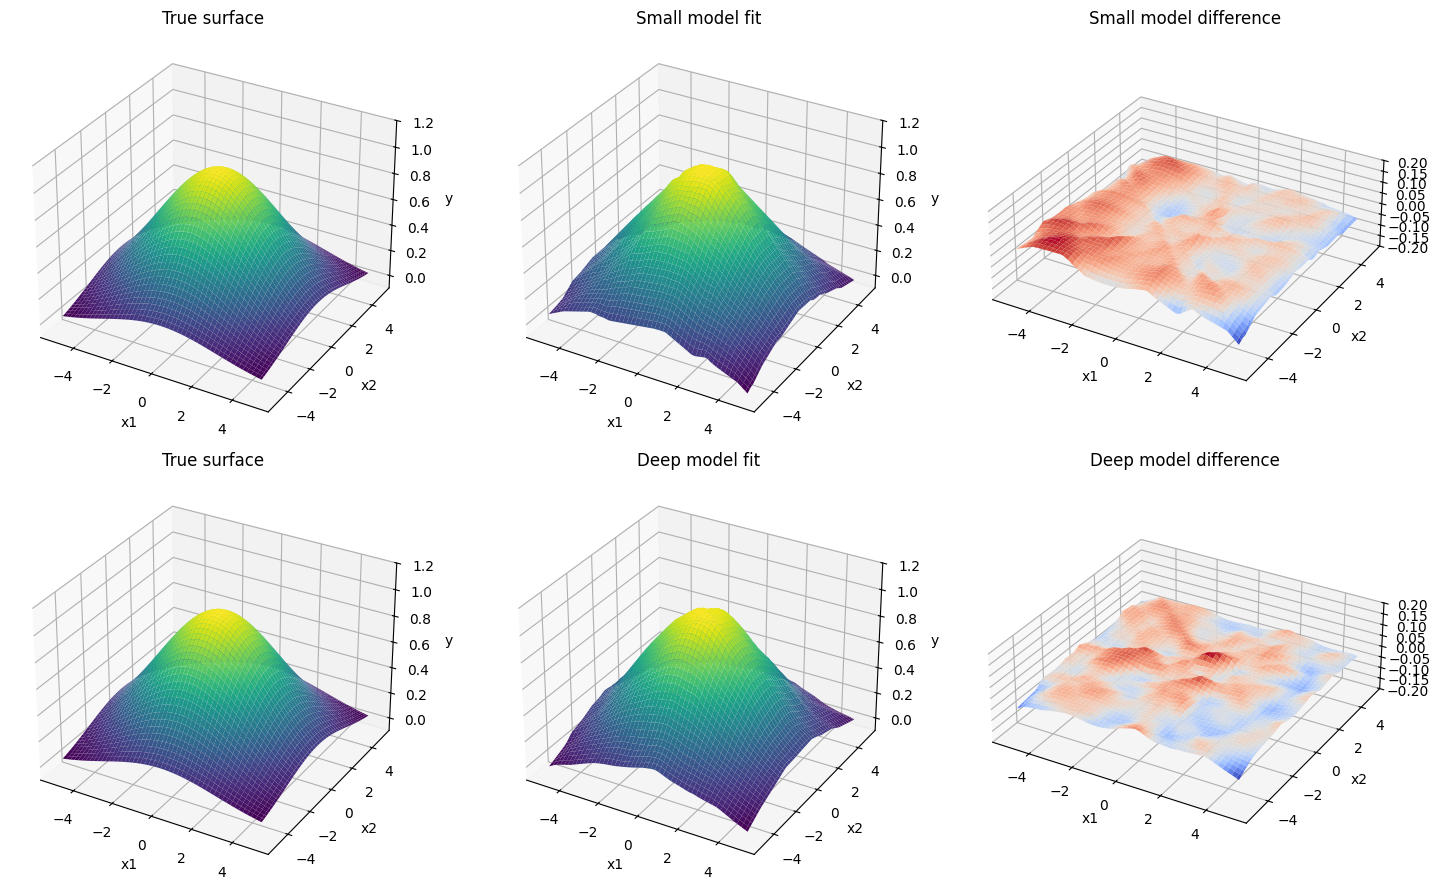

In [7]:
# Make a regular grid covering the same input region
grid_axis = torch.linspace(-5, 5, 100)
grid_x1, grid_x2 = torch.meshgrid(grid_axis, grid_axis, indexing="ij")
grid_points = torch.stack(
    [grid_x1.reshape(-1), grid_x2.reshape(-1)],
    dim=1
)

# Evaluate the true function and both models
with torch.no_grad():
    true_surface = torch.exp(
        -(grid_points ** 2).sum(dim=1, keepdim=True) / 16
    ).reshape(100, 100)

    small_surface = model_small(grid_points).reshape(100, 100)
    deep_surface = model_deep(grid_points).reshape(100, 100)

small_difference = small_surface - true_surface
deep_difference = deep_surface - true_surface
error_limit = max(
    small_difference.abs().max().item(),
    deep_difference.abs().max().item()
)

# Convert to NumPy for plotting
gx1 = grid_x1.numpy()
gx2 = grid_x2.numpy()

plots = [
    ("True surface", true_surface.numpy(), "viridis", False),
    ("Small model fit", small_surface.numpy(), "viridis", False),
    ("Small model difference", small_difference.numpy(), "coolwarm", True),
    ("True surface", true_surface.numpy(), "viridis", False),
    ("Deep model fit", deep_surface.numpy(), "viridis", False),
    ("Deep model difference", deep_difference.numpy(), "coolwarm", True),
]

fig = plt.figure(figsize=(15, 9))

for i, (title, z_values, color_map, is_difference) in enumerate(plots, start=1):
    ax = fig.add_subplot(2, 3, i, projection="3d")
    ax.plot_surface(gx1, gx2, z_values, cmap=color_map, edgecolor="none")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")

    if is_difference:
      ax.set_zlim(-0.2, 0.2)
      ax.set_box_aspect((1, 1, 0.35))
    else:
        ax.set_zlim(-0.1, 1.2)

plt.tight_layout()
plt.show()

# Section 7

(a)  

In [35]:
# Generate 5 new, independent inputs and noisy targets
X_val = 10 * torch.rand(5, 2) - 5
y_val_clean = torch.exp(-(X_val ** 2).sum(dim=1, keepdim=True) / 16)
y_val = y_val_clean + sigma_noise * torch.randn(5, 1)

# Evaluate both trained models without changing their parameters
with torch.no_grad():
    small_predictions = model_small(X_val)
    deep_predictions = model_deep(X_val)

    rmse_small_val = torch.sqrt(
        torch.mean((small_predictions - y_val) ** 2)
    ).item()

    rmse_deep_val = torch.sqrt(
        torch.mean((deep_predictions - y_val) ** 2)
    ).item()

print("Small model validation RMSE:", rmse_small_val)
print("Deep model validation RMSE:", rmse_deep_val)

selected_model = (
    "Small model" if rmse_small_val < rmse_deep_val else "Deep model"
)
print("Selected using the 5 validation examples:", selected_model)

Small model validation RMSE: 0.048795435577631
Deep model validation RMSE: 0.045028503984212875
Selected using the 5 validation examples: Deep model


(b)

In [36]:
# Identify the model selected using the 5 validation examples
if rmse_small_val < rmse_deep_val:
    selected_model_obj = model_small
    selected_model_name = "Small model"
    selected_val_rmse = rmse_small_val
else:
    selected_model_obj = model_deep
    selected_model_name = "Deep model"
    selected_val_rmse = rmse_deep_val

# Generate 25,000 new independent test examples
N_test = 25_000
X_test = 10 * torch.rand(N_test, 2) - 5
y_test_clean = torch.exp(-(X_test ** 2).sum(dim=1, keepdim=True) / 16)
y_test = y_test_clean + sigma_noise * torch.randn(N_test, 1)

# Estimate the selected model's RMSE
with torch.no_grad():
    test_predictions = selected_model_obj(X_test)
    rmse_test = torch.sqrt(
        torch.mean((test_predictions - y_test) ** 2)
    ).item()

print("Selected model:", selected_model_name)
print("5-example validation RMSE:", selected_val_rmse)
print("25,000-example test RMSE:", rmse_test)

Selected model: Deep model
5-example validation RMSE: 0.045028503984212875
25,000-example test RMSE: 0.045700445771217346


(c) Five-example validation RMSE was 0.04503, slightly lower than the 25,000-example test RMSE of 0.04570. So the validation estimate was slightly optimistic, by about 0.00067. The difference is small, but with only five examples, the estimate can vary a lot by chance.

(d)

In [37]:
if selected_model_name == "Small model":
    rejected_model_obj = model_deep
    rejected_model_name = "Deep model"
else:
    rejected_model_obj = model_small
    rejected_model_name = "Small model"

with torch.no_grad():
    rejected_predictions = rejected_model_obj(X_test)
    rmse_rejected_test = torch.sqrt(
        torch.mean((rejected_predictions - y_test) ** 2)
    ).item()

print("Rejected model:", rejected_model_name)
print("Rejected model test RMSE:", rmse_rejected_test)
print("Selected model test RMSE:", rmse_test)

Rejected model: Small model
Rejected model test RMSE: 0.04419513791799545
Selected model test RMSE: 0.045700445771217346


The rejected small model achieved a test RMSE of 0.04420, compared with 0.04570 for the selected deep model. Thus, on the 25,000-example test set, the rejected model performed slightly better. The five-example validation set selected the deep model, but was too small to provide a reliable comparison.

# Section 8

Generate and split the new dataset

In [8]:
from torch.utils.data import TensorDataset, DataLoader

N_E = 100
sigma_noise_E = 0.04

X_all_E = 10 * torch.rand(N_E, 2) - 5
y_clean_E = torch.exp(
    -(X_all_E ** 2).sum(dim=1, keepdim=True) / 16
)
y_all_E = y_clean_E + sigma_noise_E * torch.randn(N_E, 1)

# Randomly assign 50 examples to training, 25 to validation, 25 to test
indices_E = torch.randperm(N_E)
train_idx_E = indices_E[:50]
val_idx_E = indices_E[50:75]
test_idx_E = indices_E[75:]

X_train_E, y_train_E = X_all_E[train_idx_E], y_all_E[train_idx_E]
X_val_E, y_val_E = X_all_E[val_idx_E], y_all_E[val_idx_E]
X_test_E, y_test_E = X_all_E[test_idx_E], y_all_E[test_idx_E]

train_dataset_E = TensorDataset(X_train_E, y_train_E)
train_loader_E = DataLoader(
    train_dataset_E,
    batch_size=10,
    shuffle=True
)

print("Train examples:", len(X_train_E))
print("Validation examples:", len(X_val_E))
print("Test examples:", len(X_test_E))
print("Mini-batches per epoch:", len(train_loader_E))

Train examples: 50
Validation examples: 25
Test examples: 25
Mini-batches per epoch: 5


We’ll use the small 2–40–1 architecture

In [9]:
model_E = nn.Sequential(
    nn.Linear(2, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
)

criterion_E = nn.MSELoss()
learning_rate_E = 0.001
optimizer_E = torch.optim.Adam(
    model_E.parameters(),
    lr=learning_rate_E
)

training_costs_E = []
validation_rmse_E = []

print("Architecture:", model_E)
print("Trainable parameters:",
      sum(p.numel() for p in model_E.parameters()))
print("Learning rate:", learning_rate_E)

Architecture: Sequential(
  (0): Linear(in_features=2, out_features=40, bias=True)
  (1): ReLU()
  (2): Linear(in_features=40, out_features=1, bias=True)
)
Trainable parameters: 161
Learning rate: 0.001


Now training one epoch at a time, checking validation RMSE after every epoch. Starting at epoch 6, the rule compares the average RMSE from the latest three epochs with the average from the three before them. Since lower RMSE is better, we stop if the newer average is higher. I’ve set 400 epochs as a maximum safeguard; the stopping rule may end training earlier.

In [11]:
max_epochs_E = 400
epoch_train_mse_E = []
stop_epoch_E = None

for epoch in range(1, max_epochs_E + 1):
    # Train for one epoch
    total_cost = 0.0
    examples_seen = 0

    for x_batch, y_batch in train_loader_E:
        optimizer_E.zero_grad()

        predictions = model_E(x_batch)
        loss = criterion_E(predictions, y_batch)

        loss.backward()
        optimizer_E.step()

        training_costs_E.append(loss.item())
        total_cost += loss.item() * len(x_batch)
        examples_seen += len(x_batch)

    epoch_train_mse_E.append(total_cost / examples_seen)

    # Measure validation RMSE without changing the model
    with torch.no_grad():
        val_predictions = model_E(X_val_E)
        val_rmse = torch.sqrt(
            torch.mean((val_predictions - y_val_E) ** 2)
        ).item()

    validation_rmse_E.append(val_rmse)

    # Apply the assignment's stopping rule starting after epoch 6
    if epoch >= 6:
        earlier_avg = sum(validation_rmse_E[-6:-3]) / 3
        recent_avg = sum(validation_rmse_E[-3:]) / 3

        if recent_avg > earlier_avg:
            stop_epoch_E = epoch
            break

if stop_epoch_E is None:
    stop_epoch_E = len(validation_rmse_E)

print("Stopped at epoch:", stop_epoch_E)
print("Validation RMSE at stopping:", validation_rmse_E[-1])

if stop_epoch_E >= 6:
    print("Average RMSE, earlier 3 epochs:",
          sum(validation_rmse_E[-6:-3]) / 3)
    print("Average RMSE, recent 3 epochs:",
          sum(validation_rmse_E[-3:]) / 3)

Stopped at epoch: 6
Validation RMSE at stopping: 0.09814104437828064
Average RMSE, earlier 3 epochs: 0.09858670582373937
Average RMSE, recent 3 epochs: 0.09910896420478821


Now evaluating the stopped model on the 25 held-out test examples.

Stopping epoch: 6
RMSE on 25 test examples: 0.10808022320270538


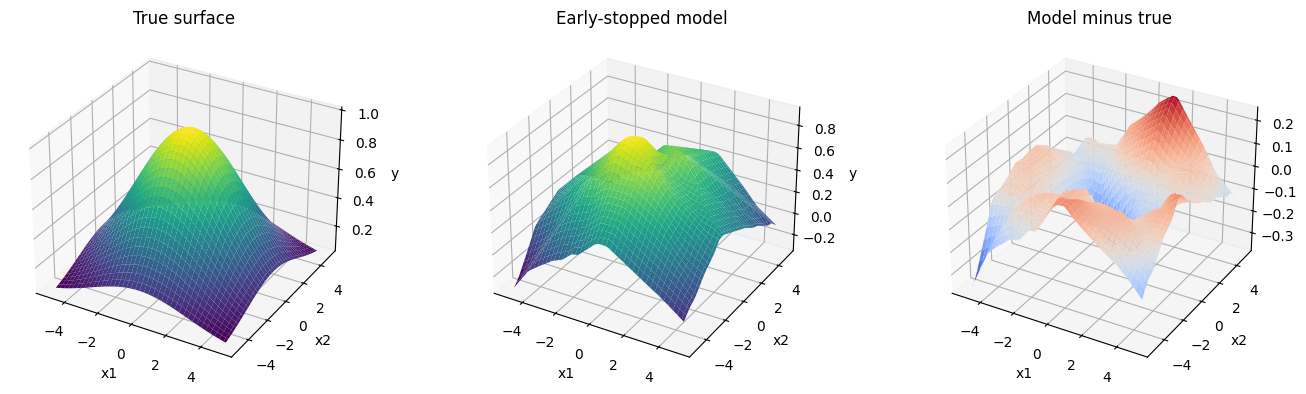

In [12]:
# Test RMSE on the 25 held-out examples
with torch.no_grad():
    test_predictions_E = model_E(X_test_E)
    rmse_test_25_E = torch.sqrt(
        torch.mean((test_predictions_E - y_test_E) ** 2)
    ).item()

print("Stopping epoch:", stop_epoch_E)
print("RMSE on 25 test examples:", rmse_test_25_E)

# Evaluate the final model over a grid for the 3D plot
grid_axis_E = torch.linspace(-5, 5, 80)
grid_x1_E, grid_x2_E = torch.meshgrid(
    grid_axis_E, grid_axis_E, indexing="ij"
)
grid_points_E = torch.stack(
    [grid_x1_E.reshape(-1), grid_x2_E.reshape(-1)],
    dim=1
)

true_surface_E = torch.exp(
    -(grid_points_E ** 2).sum(dim=1) / 16
).reshape(80, 80)

with torch.no_grad():
    fitted_surface_E = model_E(grid_points_E).reshape(80, 80)

difference_E = fitted_surface_E - true_surface_E

# Plot the true surface, the stopped model, and their difference
fig = plt.figure(figsize=(14, 4))
surfaces_E = [
    ("True surface", true_surface_E),
    ("Early-stopped model", fitted_surface_E),
    ("Model minus true", difference_E),
]

for i, (title, values) in enumerate(surfaces_E, start=1):
    ax = fig.add_subplot(1, 3, i, projection="3d")
    ax.plot_surface(
        grid_x1_E.numpy(),
        grid_x2_E.numpy(),
        values.numpy(),
        cmap="coolwarm" if i == 3 else "viridis",
        edgecolor="none"
    )
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("y")

plt.tight_layout()
plt.show()

Now estimating the stopped model’s performance on 25,000 new examples

In [13]:
N_big_test_E = 25_000

X_big_test_E = 10 * torch.rand(N_big_test_E, 2) - 5
y_big_clean_E = torch.exp(
    -(X_big_test_E ** 2).sum(dim=1, keepdim=True) / 16
)
y_big_test_E = y_big_clean_E + sigma_noise_E * torch.randn(N_big_test_E, 1)

with torch.no_grad():
    big_test_predictions_E = model_E(X_big_test_E)
    rmse_big_test_E = torch.sqrt(
        torch.mean((big_test_predictions_E - y_big_test_E) ** 2)
    ).item()

print("RMSE on 25 examples:   ", rmse_test_25_E)
print("RMSE on 25,000 examples:", rmse_big_test_E)
print("Difference:", rmse_test_25_E - rmse_big_test_E)

RMSE on 25 examples:    0.10808022320270538
RMSE on 25,000 examples: 0.1079178974032402
Difference: 0.00016232579946517944


Running it for 4 times

In [14]:
trial_results_E = [{
    "trial": 1,
    "stop_epoch": stop_epoch_E,
    "validation_RMSE": validation_rmse_E[-1],
    "test_25_RMSE": rmse_test_25_E,
    "test_25000_RMSE": rmse_big_test_E,
}]

def run_task_E_trial(seed, max_epochs=400):
    torch.manual_seed(seed)
    sigma = 0.04

    # New dataset and random 50/25/25 split
    X_all = 10 * torch.rand(100, 2) - 5
    y_clean = torch.exp(-(X_all ** 2).sum(dim=1, keepdim=True) / 16)
    y_all = y_clean + sigma * torch.randn(100, 1)

    indices = torch.randperm(100)
    train_idx, val_idx, test_idx = indices[:50], indices[50:75], indices[75:]

    X_train, y_train = X_all[train_idx], y_all[train_idx]
    X_val, y_val = X_all[val_idx], y_all[val_idx]
    X_test, y_test = X_all[test_idx], y_all[test_idx]

    loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=10,
        shuffle=True
    )

    # Fresh 2-40-1 model
    model = nn.Sequential(
        nn.Linear(2, 40),
        nn.ReLU(),
        nn.Linear(40, 1)
    )
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    val_history = []

    for epoch in range(1, max_epochs + 1):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            val_rmse = torch.sqrt(
                torch.mean((model(X_val) - y_val) ** 2)
            ).item()
        val_history.append(val_rmse)

        if epoch >= 6:
            earlier_avg = sum(val_history[-6:-3]) / 3
            recent_avg = sum(val_history[-3:]) / 3
            if recent_avg > earlier_avg:
                break

    with torch.no_grad():
        test_25_rmse = torch.sqrt(
            torch.mean((model(X_test) - y_test) ** 2)
        ).item()

        X_big = 10 * torch.rand(25_000, 2) - 5
        y_big = (
            torch.exp(-(X_big ** 2).sum(dim=1, keepdim=True) / 16)
            + sigma * torch.randn(25_000, 1)
        )
        test_25000_rmse = torch.sqrt(
            torch.mean((model(X_big) - y_big) ** 2)
        ).item()

    return {
        "stop_epoch": epoch,
        "validation_RMSE": val_history[-1],
        "test_25_RMSE": test_25_rmse,
        "test_25000_RMSE": test_25000_rmse,
    }


for trial_number, seed in enumerate([101, 102, 103], start=2):
    result = run_task_E_trial(seed)
    result["trial"] = trial_number
    trial_results_E.append(result)

for result in trial_results_E:
    print(result)

{'trial': 1, 'stop_epoch': 6, 'validation_RMSE': 0.09814104437828064, 'test_25_RMSE': 0.10808022320270538, 'test_25000_RMSE': 0.1079178974032402}
{'stop_epoch': 165, 'validation_RMSE': 0.06457925587892532, 'test_25_RMSE': 0.07926999032497406, 'test_25000_RMSE': 0.06764236092567444, 'trial': 2}
{'stop_epoch': 260, 'validation_RMSE': 0.08072046935558319, 'test_25_RMSE': 0.06446527689695358, 'test_25000_RMSE': 0.06847590208053589, 'trial': 3}
{'stop_epoch': 98, 'validation_RMSE': 0.05843028798699379, 'test_25_RMSE': 0.050499796867370605, 'test_25000_RMSE': 0.06164076179265976, 'trial': 4}


| Trial | Stopping epoch | Validation RMSE | Test RMSE (25) | Test RMSE (25,000) |
|---:|---:|---:|---:|---:|
| 1 | 6 | 0.09814 | 0.10808 | 0.10792 |
| 2 | 165 | 0.06458 | 0.07927 | 0.06764 |
| 3 | 260 | 0.08072 | 0.06447 | 0.06848 |
| 4 | 98 | 0.05843 | 0.05050 | 0.06164 |



Across the four runs, stopping occurred between epochs 6 and 260. The RMSE estimated from 25 test examples varied from 0.05050 to 0.10808. It was close to the 25,000-example estimate in Trial 1, higher in Trial 2, and lower in Trials 3 and 4. This shows that a 25-example test set can give a variable estimate. The 25,000-example estimate is more stable for each trained model. Performance also varied between runs because each used a different small training set and initialization.

Personal reflections and feedback

(a) A FANN is a reasonable choice because it can learn nonlinear relationships between inputs and outputs. We do not need to assume that the relationship is bell-shaped beforehand. With a suitable architecture, enough data, and good training, a FANN can approximate many different response surfaces.

(b) A validation set contains examples that are not used to update the model’s weights. We use it to estimate how well the model performs on unseen data, help decide when to stop training, and compare different model architectures. It cannot guarantee that a model has not overfit, and a very small validation set can give an unreliable estimate. Having a separate test set gives a final performance estimate.

(c) Before training, we usually do not know how much model complexity is needed to capture the relationship. A model that is too simple may underfit, while a more complex model may fit the training data well but overfit. In my results, the small and deep models had similar training MSEs (about 0.00166 and 0.00157). The five-example validation set selected the deep model, but the 25,000-example test set showed slightly better performance for the small model. This shows why model complexity should be judged using data the model was not trained on.

(d) A very flexible model trained on too little data can overfit, it may learn the particular noise in the training examples and perform worse on new data. A model that is too simple may underfit because it cannot represent the underlying pattern. More training data generally reduces overfitting risk, while more model flexibility can increase it. Both depend on the relationship between the data, its noise, and the model.

(e) I did not find any part of the assignment particularly frustrating but some concpets took time to understand.

(f) I would suggest offering several datasets with different relationships and noise levels. This would let students compare how model architecture and performance change across different kinds of problems.

(g) No, I did not spend more than 20 hours.
